In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pda
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

In [3]:
# 도미
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [ ]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

data = [[l,w] for l,w in zip(length,weight)]
# data = np.column_stack((length,weight))
label = [1]*35 + [0]*14

train_data, test_data, train_label, test_label = train_test_split(data,label,stratify=label,test_size=0.2)


In [34]:
train_data = np.array(train_data)
test_data = np.array(test_data)

test_data

array([[   9.8,    6.7],
       [  33. ,  700. ],
       [  29.7,  500. ],
       [  34. ,  575. ],
       [  41. ,  975. ],
       [  38.5,  955. ],
       [  37. , 1000. ],
       [  11.2,    9.8],
       [  10.5,    7.5],
       [  36. ,  714. ]])

In [ ]:
# mean = np.mean(train_data, axis=0)      #평균 array([ 27.71538462, 472.86666667])
# std = np.std(train_data, axis=0)        #표준편차 array([ 10.38177739, 338.50110808])
# #mean
# #std

In [ ]:
# #표준화(스케일링) 진행: (데이터 - 평균) / 표준편차
# train_scaled = (train_data - mean) / std

In [35]:
#정규화작업 : 위에서 한 작업을 한번에 하는 모듈
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)
new_scaled = ss.transform([[25,120]])
new_scaled

array([[-0.18642409, -0.98896241]])

[[0.40577674 0.57843526 0.74436995 0.90498085 1.02879604]] [[31  3  1 38 15]]


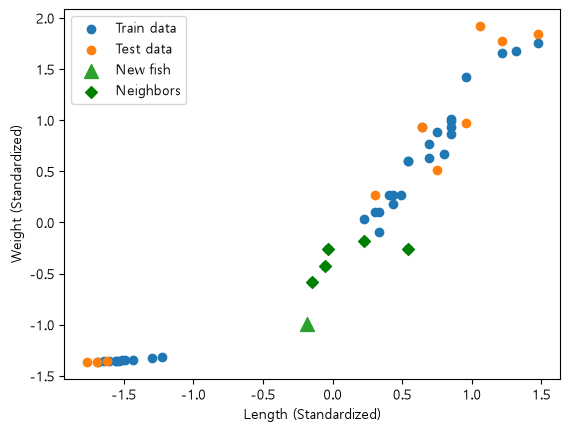

In [40]:
clf = KNeighborsClassifier()
clf.fit(train_scaled, train_label)

result = clf.predict(test_scaled)
score = clf.score(test_scaled, test_label)


#이웃찾기
distances,indexes = clf.kneighbors(new_scaled)
print(distances, indexes)
#결과값 [[0.36246599 0.51758943 0.93175706 0.93649642 1.00759731]] [[32 11 13 19  3]]

plt.scatter(train_scaled[:, 0], train_scaled[:, 1], label='Train data')
plt.scatter(test_scaled[:, 0], test_scaled[:, 1], label='Test data')

plt.scatter(new_scaled[0, 0], new_scaled[0, 1], marker='^', s=100, label='New fish')

plt.scatter(train_scaled[indexes, 0], train_scaled[indexes, 1], marker='D', color='green', label='Neighbors')
plt.xlabel('Length (Standardized)')
plt.ylabel('Weight (Standardized)')
plt.legend()
plt.show()